In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from pathlib import Path

In [33]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

 

In [34]:
population_file = PROCESSED_DATA_DIR / "ghana_district_population_2021.csv"

population_df = pd.read_csv(population_file)
district_df = population_df.copy()

In [7]:
# Create a separate dataset for district-level analysis
district_analysis = district_df.copy()

# Rank districts from highest to lowest population
district_analysis = district_analysis.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)

# Assign population ranking
district_analysis.insert(
    0,
    "rank",
    range(1, len(district_analysis) + 1)
)

# Display the top 10 most populated districts
print("TOP 10 MOST POPULATED DISTRICTS")
print("-" * 65)

display(district_analysis.head(10))

TOP 10 MOST POPULATED DISTRICTS
-----------------------------------------------------------------


,rank,region,district,population
0,1,Ashanti,Kumasi Metropolitan Area (KMA),443981
1,2,Greater Accra,Kpone Katamanso Municipal,412828
2,3,Northern,Tamale Metropolitan Area (TMA),374744
3,4,Greater Accra,Ga South Municipal,350121
4,5,Northern,Sagnarigu Municipal,341711
5,6,Greater Accra,Ga Central Municipal,332232
6,7,Greater Accra,Ga West Municipal,314299
7,8,Central,Gomoa East,308697
8,9,Ashanti,Kwabre East,296814
9,10,Greater Accra,Accra Metropolitan Area (AMA),284124


In [8]:
# Display the 10 least populated districts
print("BOTTOM 10 LEAST POPULATED DISTRICTS")
print("-" * 65)

display(
    district_analysis.tail(10).sort_values(
        by="population",
        ascending=True
    )
)

BOTTOM 10 LEAST POPULATED DISTRICTS
-----------------------------------------------------------------


,rank,region,district,population
260,261,Bono,Banda,28179
259,260,Oti,Guan,28238
258,259,Volta,Akatsi North,32755
257,258,Ashanti,Sekyere Afram Plains,33226
256,257,Eastern,Birim South,35654
255,256,Upper East,Builsa South,36575
254,255,Western North,Suaman,38268
253,254,Volta,Adaklu,38649
252,253,Upper West,Daffiama Bussie Issa,38754
251,252,Upper East,Bolgatanga East,38824


In [9]:
# Calculate district population statistics
total_districts = district_analysis["district"].nunique()

average_population = district_analysis["population"].mean()

median_population = district_analysis["population"].median()

highest_population = district_analysis["population"].max()

lowest_population = district_analysis["population"].min()

population_range = highest_population - lowest_population

# Display summary
print("=" * 60)
print("GHANA DISTRICT POPULATION SUMMARY (2021)")
print("=" * 60)

print(f"Number of districts: {total_districts:,}")
print(f"Average district population: {average_population:,.0f}")
print(f"Median district population: {median_population:,.0f}")
print(f"Highest district population: {highest_population:,}")
print(f"Lowest district population: {lowest_population:,}")
print(f"Population range: {population_range:,}")

print("=" * 60)

GHANA DISTRICT POPULATION SUMMARY (2021)
Number of districts: 261
Average district population: 118,130
Median district population: 100,851
Highest district population: 443,981
Lowest district population: 28,179
Population range: 415,802


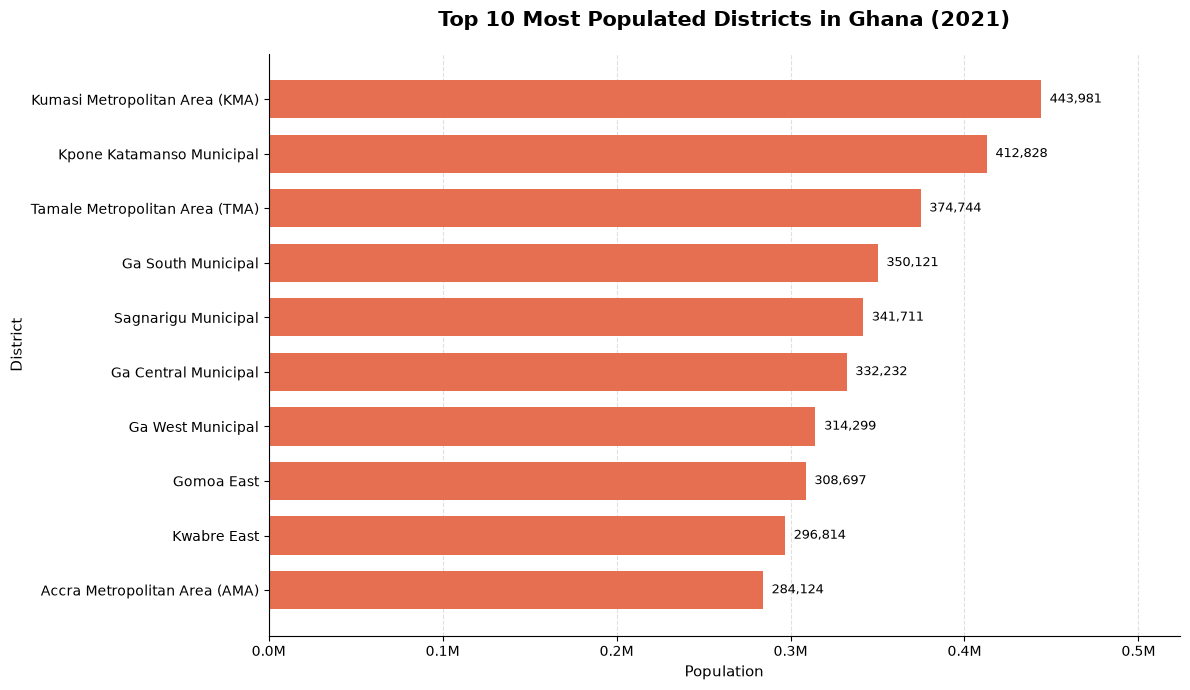

In [10]:
# Select the top 10 most populated districts
top_10_districts = district_analysis.head(10).copy()

# Arrange districts in ascending order for horizontal plotting
chart_data = top_10_districts.sort_values(
    by="population",
    ascending=True
)

# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 7))

# Create horizontal bar chart
bars = ax.barh(
    chart_data["district"],
    chart_data["population"],
    color="#E76F51",
    height=0.7
)

# Format population labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 5000,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

# Add chart title
ax.set_title(
    "Top 10 Most Populated Districts in Ghana (2021)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Add axis labels
ax.set_xlabel("Population", fontsize=11)
ax.set_ylabel("District", fontsize=11)

# Format horizontal axis in millions
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Create space for population labels
ax.set_xlim(
    0,
    chart_data["population"].max() * 1.18
)

plt.tight_layout()

In [35]:
# Define output file
output_dir = PROJECT_ROOT / "outputs" / "charts"
district_chart_path = (
    output_dir / "top_10_most_populated_districts.png"
)

# Save the specific figure
fig.savefig(
    district_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Display chart
plt.show()

# Confirm saved file
print("District population chart saved successfully!")
print("File size:", f"{district_chart_path.stat().st_size:,} bytes")

District population chart saved successfully!
File size: 162,882 bytes


In [13]:
# Calculate total district population for each region
district_population_by_region = (
    district_analysis
    .groupby("region")["population"]
    .sum()
    .reset_index()
)

# Rename population column
district_population_by_region = (
    district_population_by_region.rename(
        columns={"population": "district_population"}
    )
)

# Sort regions by district population
district_population_by_region = (
    district_population_by_region.sort_values(
        by="district_population",
        ascending=False
    ).reset_index(drop=True)
)

# Display results
display(district_population_by_region)

,region,district_population
0,Greater Accra,5455692
1,Ashanti,5440463
2,Eastern,2925653
3,Central,2859821
4,Northern,2310928
5,Western,2060585
6,Volta,1659040
7,Upper East,1301226
8,Bono,1208649
9,Bono East,1203400


In [18]:
# Define Ghana's 16 administrative regions
ghana_regions = [
    "Western",
    "Central",
    "Greater Accra",
    "Volta",
    "Eastern",
    "Ashanti",
    "Western North",
    "Ahafo",
    "Bono",
    "Bono East",
    "Oti",
    "Northern",
    "Savannah",
    "North East",
    "Upper East",
    "Upper West"
]

# Extract regional population records
regional_population = population_df[
    population_df["region"].isin(ghana_regions)
].copy()

# Display regional population records
display(regional_population)

# Calculate the number of regions
print("Number of regions:", regional_population["region"].nunique())

# Calculate combined regional population
print(
    "Combined regional population:",
    f"{regional_population['population'].sum():,}"
)

,region,district,population
0,Western,Jomoro Municipal,126576
1,Western,Ellembelle,120893
2,Western,Nzema East Municipal,94621
3,Western,Ahanta West Municipal,153140
4,Western,Effia Kwesimintsim Municipal,173975
...,...,...,...
256,Upper West,Sissala West,63828
257,Upper West,Jirapa Municipal,91279
258,Upper West,Lawra Municipal,58433
259,Upper West,Lambussie Karni,51118


Number of regions: 16
Combined regional population: 30,832,019


In [19]:
ghana_regions = [
    "Western",
    "Central",
    "Greater Accra",
    "Volta",
    "Eastern",
    "Ashanti",
    "Western North",
    "Ahafo",
    "Bono",
    "Bono East",
    "Oti",
    "Northern",
    "Savannah",
    "North East",
    "Upper East",
    "Upper West"
]

# Extract regional population records
regional_population = population_df[
    population_df["region"].isin(ghana_regions)
].copy()

# Merge district totals with official regional population
regional_analysis = regional_population.copy()
regional_comparison = regional_population[
    ["region", "population"]
].merge(
    district_population_by_region,
    on="region",
    how="left"
)

# Calculate difference
regional_comparison["difference"] = (
    regional_comparison["population"] -
    regional_comparison["district_population"]
)

# Sort by official regional population
regional_comparison = regional_comparison.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)

# Display comparison
display(regional_comparison)

# Check whether all regional totals match
print(
    "All regional totals match:",
    regional_comparison["difference"].eq(0).all()
)

,region,population,district_population,difference
0,Ashanti,443981,5440463,-4996482
1,Greater Accra,412828,5455692,-5042864
2,Northern,374744,2310928,-1936184
3,Greater Accra,350121,5455692,-5105571
4,Northern,341711,2310928,-1969217
...,...,...,...,...
256,Eastern,35654,2925653,-2889999
257,Ashanti,33226,5440463,-5407237
258,Volta,32755,1659040,-1626285
259,Oti,28238,747248,-719010


All regional totals match: False


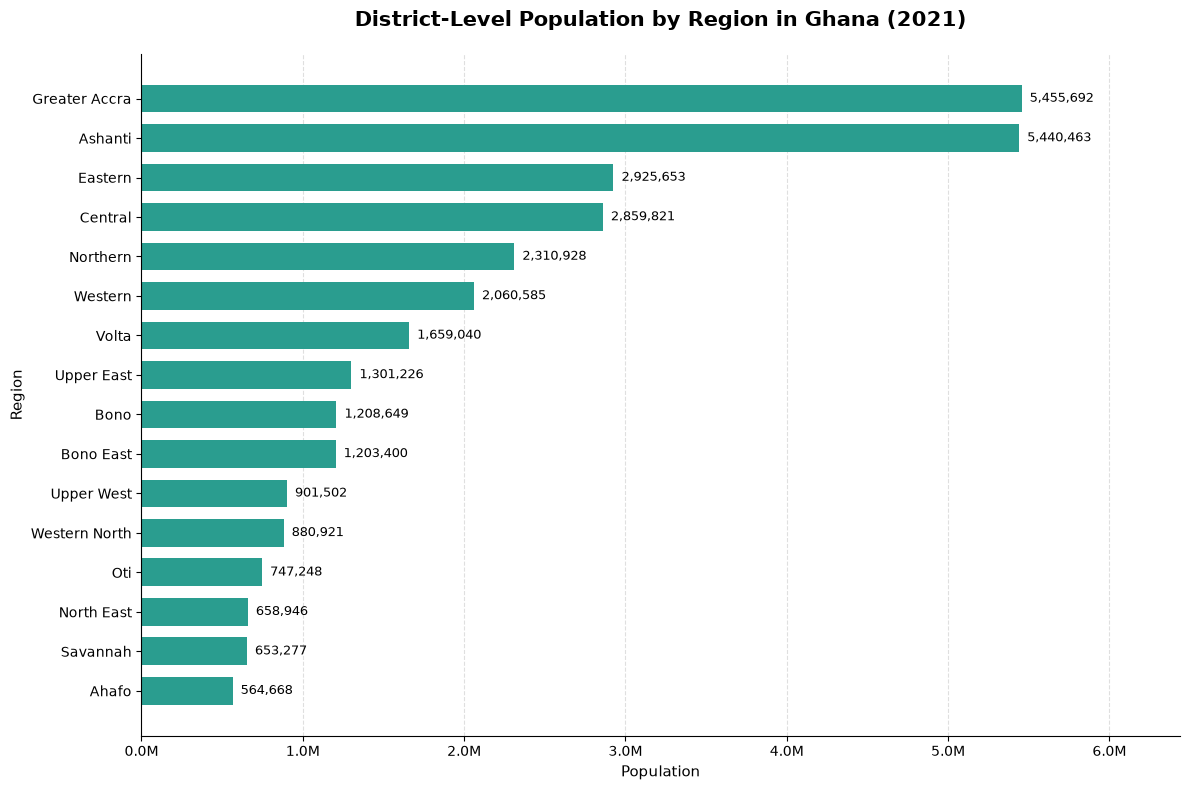

In [20]:
# Prepare chart data
chart_data = district_population_by_region.sort_values(
    by="district_population",
    ascending=True
)

# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 8))

# Create horizontal bar chart
bars = ax.barh(
    chart_data["region"],
    chart_data["district_population"],
    color="#2A9D8F",
    height=0.7
)

# Add population labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 50000,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

# Add chart title
ax.set_title(
    "District-Level Population by Region in Ghana (2021)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Axis labels
ax.set_xlabel("Population", fontsize=11)
ax.set_ylabel("Region", fontsize=11)

# Format population axis in millions
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add space for labels
ax.set_xlim(
    0,
    chart_data["district_population"].max() * 1.18
)

plt.tight_layout()

In [36]:
# Define output file
regional_district_chart_path = (
    output_dir / "district_population_by_region.png"
)

# Save figure
fig.savefig(
    regional_district_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Display chart
plt.show()

print("Chart saved successfully!")
print("File size:", f"{regional_district_chart_path.stat().st_size:,} bytes")

Chart saved successfully!
File size: 162,882 bytes


In [22]:
# Calculate descriptive statistics
district_statistics = district_analysis["population"].describe()

# Display results
print("DISTRICT POPULATION DESCRIPTIVE STATISTICS")
print("=" * 55)

display(district_statistics.to_frame(name="population"))

DISTRICT POPULATION DESCRIPTIVE STATISTICS


,population
count,261.000000
mean,118130.340996
std,68165.836638
min,28179.000000
25%,73330.000000
50%,100851.000000
75%,140264.000000
max,443981.000000


In [23]:
# Calculate additional statistics
district_mean = district_analysis["population"].mean()
district_median = district_analysis["population"].median()
district_std = district_analysis["population"].std()

# Count districts above and below the mean
above_average = (
    district_analysis["population"] > district_mean
).sum()

below_average = (
    district_analysis["population"] < district_mean
).sum()

equal_average = (
    district_analysis["population"] == district_mean
).sum()

# Display summary
print("=" * 55)
print("DISTRICT POPULATION STATISTICAL SUMMARY")
print("=" * 55)

print(f"Mean population: {district_mean:,.2f}")
print(f"Median population: {district_median:,.2f}")
print(f"Standard deviation: {district_std:,.2f}")

print("-" * 55)
print(f"Above average: {above_average}")
print(f"Below average: {below_average}")
print(f"Equal to average: {equal_average}")

print("=" * 55)

DISTRICT POPULATION STATISTICAL SUMMARY
Mean population: 118,130.34
Median population: 100,851.00
Standard deviation: 68,165.84
-------------------------------------------------------
Above average: 95
Below average: 166
Equal to average: 0


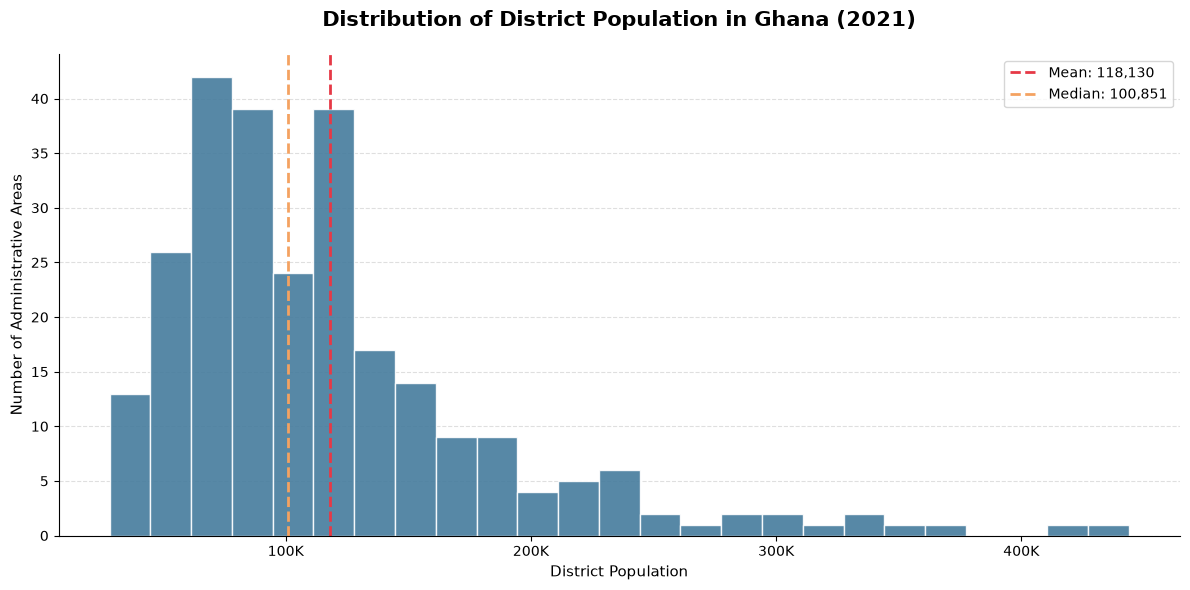

In [24]:
# Create histogram
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    district_analysis["population"],
    bins=25,
    color="#457B9D",
    edgecolor="white",
    alpha=0.9
)

# Add mean and median reference lines
ax.axvline(
    district_mean,
    color="#E63946",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {district_mean:,.0f}"
)

ax.axvline(
    district_median,
    color="#F4A261",
    linestyle="--",
    linewidth=2,
    label=f"Median: {district_median:,.0f}"
)

# Add chart title and labels
ax.set_title(
    "Distribution of District Population in Ghana (2021)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("District Population", fontsize=11)
ax.set_ylabel("Number of Administrative Areas", fontsize=11)

# Format population axis
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000:.0f}K")
)

# Improve chart appearance
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()

plt.tight_layout()

In [37]:
# Define output file
district_histogram_path = (
    output_dir / "district_population_distribution.png"
)

# Save figure
fig.savefig(
    district_histogram_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Histogram saved successfully!")
print("File size:", f"{district_histogram_path.stat().st_size:,} bytes")

Histogram saved successfully!
File size: 162,882 bytes


In [26]:
# Select the 10 least populated administrative areas
bottom_10_districts = (
    district_analysis.tail(10).copy()
)

# Arrange from lowest to highest population
chart_data = bottom_10_districts.sort_values(
    by="population",
    ascending=True
)

display(chart_data)

,rank,region,district,population
260,261,Bono,Banda,28179
259,260,Oti,Guan,28238
258,259,Volta,Akatsi North,32755
257,258,Ashanti,Sekyere Afram Plains,33226
256,257,Eastern,Birim South,35654
255,256,Upper East,Builsa South,36575
254,255,Western North,Suaman,38268
253,254,Volta,Adaklu,38649
252,253,Upper West,Daffiama Bussie Issa,38754
251,252,Upper East,Bolgatanga East,38824


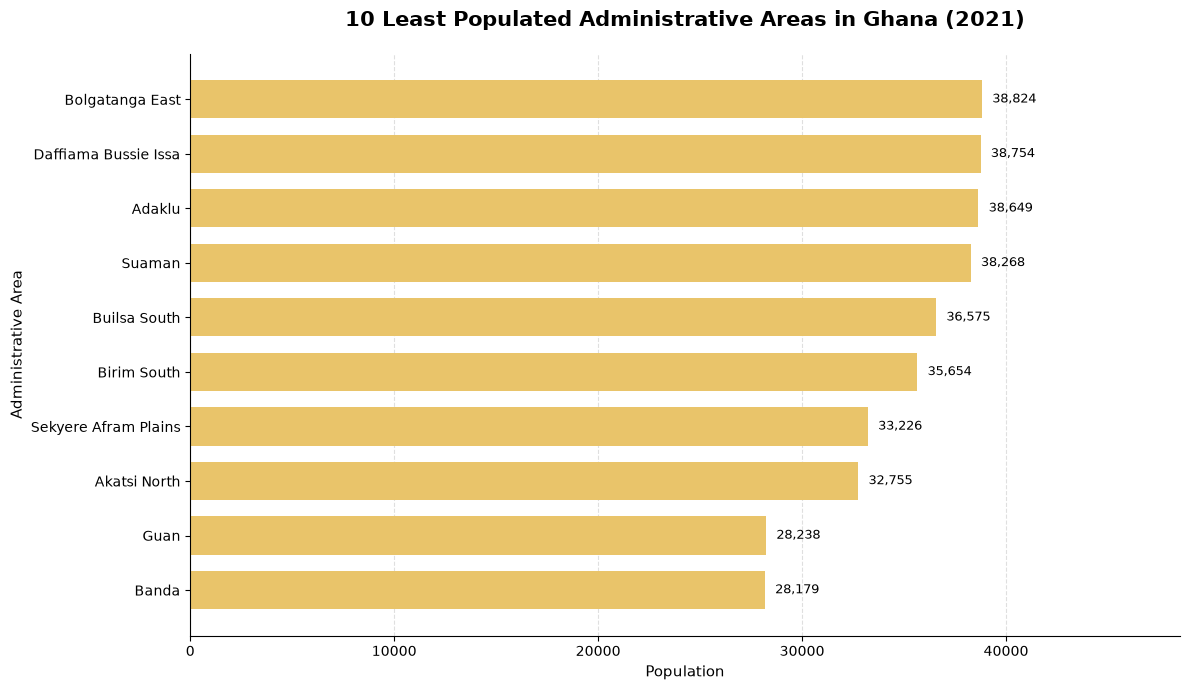

In [27]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 7))

# Create horizontal bar chart
bars = ax.barh(
    chart_data["district"],
    chart_data["population"],
    color="#E9C46A",
    height=0.7
)

# Add population labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 500,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

# Add chart title
ax.set_title(
    "10 Least Populated Administrative Areas in Ghana (2021)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Axis labels
ax.set_xlabel("Population", fontsize=11)
ax.set_ylabel("Administrative Area", fontsize=11)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Create space for population labels
ax.set_xlim(
    0,
    chart_data["population"].max() * 1.25
)

plt.tight_layout()

In [38]:
# Define output file
bottom_10_chart_path = (
    output_dir / "bottom_10_least_populated_districts.png"
)

# Save the figure
fig.savefig(
    bottom_10_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved successfully!")
print("File size:", f"{bottom_10_chart_path.stat().st_size:,} bytes")

Chart saved successfully!
File size: 162,882 bytes


In [29]:
# Retrieve population extremes
highest_district = district_analysis.iloc[0]
lowest_district = district_analysis.iloc[-1]

# Calculate population ratio
population_ratio = (
    highest_district["population"] /
    lowest_district["population"]
)

print("DISTRICT POPULATION EXTREMES")
print("=" * 55)

print(
    f"Most populated: {highest_district['district']} "
    f"({highest_district['population']:,})"
)

print(
    f"Least populated: {lowest_district['district']} "
    f"({lowest_district['population']:,})"
)

print(f"Population ratio: {population_ratio:.2f}:1")

print("=" * 55)

DISTRICT POPULATION EXTREMES
Most populated: Kumasi Metropolitan Area (KMA) (443,981)
Least populated: Banda (28,179)
Population ratio: 15.76:1


In [30]:
regional_population_summary = (
    district_analysis
    .groupby("region")["population"]
    .sum()
    .reset_index()
)

regional_population_summary = regional_population_summary.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)

display(regional_population_summary)

,region,population
0,Greater Accra,5455692
1,Ashanti,5440463
2,Eastern,2925653
3,Central,2859821
4,Northern,2310928
5,Western,2060585
6,Volta,1659040
7,Upper East,1301226
8,Bono,1208649
9,Bono East,1203400


In [31]:
print("Number of regions:", len(regional_population_summary))

print(
    "Total regional population:",
    f"{regional_population_summary['population'].sum():,}"
)

print(
    "Duplicate regions:",
    regional_population_summary["region"].duplicated().sum()
)

Number of regions: 16
Total regional population: 30,832,019
Duplicate regions: 0
